In [1]:
import os
import pandas as pd
import xarray as xr
import joblib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import gsw
from pathlib import Path

import config
from utils.data import load_dataset
from utils.gridding import df_to_gridded_da
from utils.plotting import plot_geo_panels

C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
# Load study data
data = load_dataset()

lat_min, lat_max = data.LATITUDE.min(), data.LATITUDE.max()
lon_min, lon_max = data.LONGITUDE.min(), data.LONGITUDE.max()
depths = np.sort(data.LEV_M.unique())
depths = np.append(depths, 5000)

depths_map = [0, 200, 1000]
min_year = 1952

all_model_names = ["mean", "knn", "missforest", "mlp", "remasker", "mastnet"]
models_to_plot = [m for m in all_model_names if m != "mean"]

# WOA download and preparation

In [ ]:
# WOA 23 climatologies (time-average since 1955/1965 depending on variable)
temperature = xr.load_dataset("../../data/woa/woa23_decav_t00_01.nc", decode_times=False)
salinity = xr.load_dataset("../../data/woa/woa23_decav_s00_01.nc", decode_times=False)
oxygen = xr.load_dataset("../../data/woa/woa23_all_o00_01.nc", decode_times=False)
nitrate = xr.load_dataset("../../data/woa/woa23_all_n00_01.nc", decode_times=False)
silicate = xr.load_dataset("../../data/woa/woa23_all_i00_01.nc", decode_times=False)
phosphate = xr.load_dataset("../../data/woa/woa23_all_p00_01.nc", decode_times=False)

In [ ]:
# Convert WOA in-situ temperature to potential temperature
s = salinity["s_an"].squeeze()
t = temperature["t_an"].squeeze()
p = gsw.p_from_z(-t["depth"], t["lat"])
sa = gsw.SA_from_SP(s, p, t["lon"], t["lat"])
temperature["t_an"] = gsw.pt_from_t(sa, t, p, p_ref=0.0).rename("t_an")

In [ ]:
# Global surface potential temperature map
t = temperature["t_an"].squeeze()
surface = t.sel(depth=temperature.depth[0])
plt.figure()
surface.plot()
plt.title("Surface Potential Temperature (0 m)")
plt.show()

In [ ]:
# Save to parquet (run once)
ds_dict = {
    "P_TEMPERATURE": [temperature, "t_an"],
    "P_SALINITY": [salinity, "s_an"],
    "P_OXYGEN": [oxygen, "o_an"],
    "P_NITRATE": [nitrate, "n_an"],
    "P_SILICATE": [silicate, "i_an"],
    "P_PHOSPHATE": [phosphate, "p_an"],
}

os.makedirs("../../data/woa/", exist_ok=True)
for k, (ds, var_name) in ds_dict.items():
    # Out path
    out_path = f"../../data/woa/woa_{k}.parquet"
    if Path(out_path).is_file():
        print(f"  Already exists: {out_path}")
        continue

    # Filter scope and bin depth
    da = ds[var_name].squeeze()
    filtered = da.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
    depth_avg = filtered.groupby_bins("depth", depths).mean()
    depth_avg = depth_avg.assign_coords({"depth_bins": depths[:-1]})

    # Convert to clean df and store
    depth_avg.to_dataframe(name=k).reset_index().dropna().rename(columns={"depth_bins": "LEV_M", "lat": "LATITUDE", "lon": "LONGITUDE"})[[k, "LEV_M", "LATITUDE", "LONGITUDE"]].to_parquet(out_path)
    print(f"  Saved {out_path}")

# Load pre-processed WOA

In [3]:
# Entry point for analysis runs (loads from pre-saved parquets)
woa_dict = {}
for param in config.parameters:
    woa_dict[param] = pd.read_parquet(f"../../data/woa/woa_{param}.parquet")

# Compute WOA differences

In [4]:
def compute_woa_diffs(df_rec, df_true, woa_dict, scaler_dict=None):
    """Spatial mean and std of (prediction - WOA) per (lat, lon, depth).

    WOA is a time-average, so differences are averaged over time at each location.
    Only positions that were missing in the observations and recorded after
    min_year are compared. Depth levels are pre-binned to this studie's data levels in
    the woa_dict parquets.

    Returns {"mean": DataFrame, "std": DataFrame} with columns
    LATITUDE, LONGITUDE, LEV_M, P_TEMPERATURE, P_SALINITY, ...
    """
    df_compares = []
    for parameter in config.parameters:
        temp_woa = woa_dict[parameter].copy()

        # Scale WOA data
        if scaler_dict is not None and parameter in scaler_dict:
            temp_woa[parameter + "_woa"] = scaler_dict[parameter].transform(
                temp_woa[parameter].to_numpy().reshape(-1, 1))
        else:
            temp_woa[parameter + "_woa"] = temp_woa[parameter]

        # Round lat/lon (to match this studie's data)
        temp_woa["lat_round"] = temp_woa["LATITUDE"].round(1)
        temp_woa["lon_round"] = temp_woa["LONGITUDE"].round(1)

        # Only work on initially missing data
        df_rec["was_missing"] = df_true[parameter].isna().values
        df_missing = df_rec[df_rec["was_missing"]].copy()
        df_missing = df_missing[df_missing["DATEANDTIME"] >= min_year]

        # Merge WOA and this studies's data
        df_compare = df_missing[["LEV_M", "lat_round", "lon_round", parameter]].merge(
            temp_woa[["LEV_M", "lat_round", "lon_round", parameter + "_woa"]],
            on=["LEV_M", "lat_round", "lon_round"],
            how="inner")

        # Compute diff
        df_compare[parameter] = df_compare[parameter] - df_compare[parameter + "_woa"]
        df_compare = (df_compare[[parameter, "lat_round", "lon_round", "LEV_M"]]
                      .rename(columns={"lat_round": "LATITUDE", "lon_round": "LONGITUDE"}))
        df_compares.append(df_compare)

    temp = df_compares[0]

    # Add coordinates
    for t in df_compares[1:]:
        temp = temp.merge(t, on=["LATITUDE", "LONGITUDE", "LEV_M"], how="outer")
    grp = temp.groupby(["LATITUDE", "LONGITUDE", "LEV_M"])

    return {"mean": grp.mean().reset_index(), "std": grp.std().reset_index()}

## Ablation experiments

One summary per experiment x seed

In [5]:
model_name = "mastnet"

# for model_dir in sorted(Path("output/tuning/mastnet/architecture_ablation").glob("exp*/")):
for model_dir in sorted(Path("F:/PhD/phd_repos/time_imputation/output/tuning/mastnet/architecture_ablation").glob("exp*/")):
    if model_dir.name == "exp320":
        # Different lengths: Length of values (637390) does not match length of index (32636)
        continue

    # Get prediction files and seeds
    seed_pred_files = sorted(model_dir.glob(f"{model_name}_seed*_y_pred.csv"))
    seeds = ([int(f.stem.split("seed")[1].split("_")[0]) for f in seed_pred_files]
             if seed_pred_files else [None])

    for seed in seeds:
        seed_suffix = f"_seed{seed}" if seed is not None else ""

        # Skip if this seed's results already exist
        out_plain = model_dir / f"{model_name}{seed_suffix}_woa_diff_summary.csv"
        out_scaled = model_dir / f"{model_name}{seed_suffix}_woa_diff_summary_scaled.csv"
        if out_plain.is_file() and out_scaled.is_file():
            continue

        pred_path = model_dir / f"{model_name}{seed_suffix}_y_pred.csv"
        true_path = model_dir / f"{model_name}{seed_suffix}_y_true.csv"
        if not pred_path.is_file():
            print(f"Skipping {model_dir.name} seed={seed}: no predictions found")
            continue

        print(f"Processing {model_dir.name} seed={seed}...")

        # Load predictions and true input
        y_pred = pd.read_csv(pred_path)
        y_true = pd.read_csv(true_path)

        # Clean up
        for c in ["Unnamed: 0"]:
            if c in y_pred.columns: y_pred = y_pred.drop(c, axis=1)
            if c in y_true.columns: y_true = y_true.drop(c, axis=1)

        # Unscale predictions
        scalers = joblib.load(model_dir / "scalers.joblib")
        y_pred_unscaled = y_pred.copy()
        for k, v in scalers.items():
            if k in y_pred_unscaled.columns:
                y_pred_unscaled[k] = v.inverse_transform(
                    y_pred_unscaled[k].to_numpy().reshape(-1, 1))

        # Add coordinates
        y_pred[config.coordinates] = data[config.coordinates].values
        y_pred_unscaled[config.coordinates] = data[config.coordinates].values
        y_true[config.coordinates] = data[config.coordinates].values

        # Round coordinates
        for df in [y_pred, y_pred_unscaled]:
            df["lat_round"] = df["LATITUDE"].round(1)
            df["lon_round"] = df["LONGITUDE"].round(1)

        # Compute WOA diffs per seed
        diff_unscaled = compute_woa_diffs(
            df_rec=y_pred_unscaled.copy(), df_true=y_true, woa_dict=woa_dict)
        diff_scaled = compute_woa_diffs(
            df_rec=y_pred.copy(), df_true=y_true, woa_dict=woa_dict, scaler_dict=scalers)

        # Write per-seed summary CSVs (read by ablation_evaluation.ipynb)
        for suffix, result in [("", diff_unscaled), ("_scaled", diff_scaled)]:
            rows = [{"parameter": p,
                     "MAE": result["mean"][p].abs().mean(),
                     "RMSE": np.sqrt((result["mean"][p] ** 2).mean()),
                     "std": result["std"][p].mean()}
                    for p in config.parameters if p in result["mean"].columns]
            pd.DataFrame(rows).to_csv(
                model_dir / f"{model_name}{seed_suffix}_woa_diff_summary{suffix}.csv", index=False)


Processing exp270 seed=42...
Processing exp270 seed=43...
Processing exp270 seed=44...
Processing exp270 seed=45...
Processing exp270 seed=46...
Processing exp271 seed=42...
Processing exp271 seed=43...
Processing exp271 seed=44...
Processing exp271 seed=45...
Processing exp271 seed=46...
Processing exp272 seed=42...
Processing exp272 seed=43...
Processing exp272 seed=44...
Processing exp272 seed=45...
Processing exp272 seed=46...
Processing exp273 seed=42...
Processing exp273 seed=43...
Processing exp273 seed=44...
Processing exp273 seed=45...
Processing exp273 seed=46...
Processing exp274 seed=42...
Processing exp274 seed=43...
Processing exp274 seed=44...
Processing exp274 seed=45...
Processing exp274 seed=46...
Processing exp275 seed=42...
Processing exp275 seed=43...
Processing exp275 seed=44...
Processing exp275 seed=45...
Processing exp275 seed=46...
Processing exp276 seed=42...
Processing exp276 seed=43...
Processing exp276 seed=44...
Processing exp276 seed=45...
Processing exp

## Seed-variance runs

One summary per model x seed, from experiments/seed_variance_study.py

In [5]:
seed_variance_root = Path("F:/PhD/phd_repos/time_imputation/output/testing/seed_variance/seed_variance")
seed_variance_models = ["missforest", "mlp", "remasker", "mastnet"]


for model_name in seed_variance_models:
    model_dir = seed_variance_root / model_name
    seed_pred_files = sorted(model_dir.glob(f"{model_name}_seed*_y_pred.csv"))
    if not seed_pred_files:
        print(f"Skipping {model_name}: no seed predictions found in {model_dir}")
        continue

    scalers = joblib.load(model_dir / "scalers.joblib")

    for pred_path in seed_pred_files:
        seed = int(pred_path.stem.split("seed")[1].split("_")[0])

        # Skip if this seed's results already exist
        out_plain = model_dir / f"{model_name}_seed{seed}_woa_diff_summary.csv"
        out_scaled = model_dir / f"{model_name}_seed{seed}_woa_diff_summary_scaled.csv"
        if out_plain.is_file() and out_scaled.is_file():
            continue

        true_path = model_dir / f"{model_name}_seed{seed}_y_true.csv"
        print(f"Processing {model_name} seed={seed}...")

        # Load predictions and true input
        y_pred = pd.read_csv(pred_path)
        y_true = pd.read_csv(true_path)
        for c in ["Unnamed: 0"]:
            if c in y_pred.columns: y_pred = y_pred.drop(c, axis=1)
            if c in y_true.columns: y_true = y_true.drop(c, axis=1)

        # Unscale predictions
        y_pred_unscaled = y_pred.copy()
        for k, v in scalers.items():
            if k in y_pred_unscaled.columns:
                y_pred_unscaled[k] = v.inverse_transform(
                    y_pred_unscaled[k].to_numpy().reshape(-1, 1))

        # Add coordinates
        y_pred[config.coordinates] = data[config.coordinates].values
        y_pred_unscaled[config.coordinates] = data[config.coordinates].values
        y_true[config.coordinates] = data[config.coordinates].values

        # Round coordinates
        for df in [y_pred, y_pred_unscaled]:
            df["lat_round"] = df["LATITUDE"].round(1)
            df["lon_round"] = df["LONGITUDE"].round(1)

        # Compute WOA diffs per seed
        diff_unscaled = compute_woa_diffs(
            df_rec=y_pred_unscaled.copy(), df_true=y_true, woa_dict=woa_dict)
        diff_scaled = compute_woa_diffs(
            df_rec=y_pred.copy(), df_true=y_true, woa_dict=woa_dict, scaler_dict=scalers)

        # Write per-seed summaries
        for suffix, result in [("", diff_unscaled), ("_scaled", diff_scaled)]:
            rows = [{"parameter": p,
                     "MAE": result["mean"][p].abs().mean(),
                     "RMSE": np.sqrt((result["mean"][p] ** 2).mean()),
                     "std": result["std"][p].mean()}
                    for p in config.parameters if p in result["mean"].columns]
            pd.DataFrame(rows).to_csv(
                model_dir / f"{model_name}_seed{seed}_woa_diff_summary{suffix}.csv", index=False)


Processing mastnet seed=42...
Processing mastnet seed=43...
Processing mastnet seed=44...
Processing mastnet seed=45...
Processing mastnet seed=46...


## Final models (test-set)

In [7]:
# Compute test results
res_woa = {}  # physical (unscaled) units
res_woa_scaled = {}  # normalised [0, 1] space

final_models_root = Path("F:/PhD/phd_repos/time_imputation/output/testing/")

for model_name in models_to_plot:
    print(f"Processing {model_name}...")
    model_dir = final_models_root / model_name
    y_pred = pd.read_csv(model_dir / f"model{model_name}_y_pred.csv")
    y_true = pd.read_csv(model_dir / f"model{model_name}_y_true.csv")

    # Clean up
    for c in ["Unnamed: 0"]:
        if c in y_pred.columns: y_pred = y_pred.drop(c, axis=1)
        if c in y_true.columns: y_true = y_true.drop(c, axis=1)

    # Unscale predictions
    scalers = joblib.load(model_dir / "scalers.joblib")
    y_pred_unscaled = y_pred.copy()
    for k, v in scalers.items():
        if k in y_pred_unscaled.columns:
            y_pred_unscaled[k] = v.inverse_transform(
                y_pred_unscaled[k].to_numpy().reshape(-1, 1))

    # Add coordinates
    y_pred[config.coordinates] = data[config.coordinates].values
    y_pred_unscaled[config.coordinates] = data[config.coordinates].values
    y_true[config.coordinates] = data[config.coordinates].values

    # Round coordinates
    for df in [y_pred, y_pred_unscaled]:
        df["lat_round"] = df["LATITUDE"].round(1)
        df["lon_round"] = df["LONGITUDE"].round(1)

    # Compute WOA diffs
    res_woa[model_name] = compute_woa_diffs(
        df_rec=y_pred_unscaled.copy(), df_true=y_true, woa_dict=woa_dict)
    res_woa_scaled[model_name] = compute_woa_diffs(
        df_rec=y_pred.copy(), df_true=y_true, woa_dict=woa_dict, scaler_dict=scalers)

    # Write per-model summary CSVs
    for suffix, result in [("", res_woa[model_name]), ("_scaled", res_woa_scaled[model_name])]:
        rows = [{"parameter": p,
                 "MAE": result["mean"][p].abs().mean(),
                 "RMSE": np.sqrt((result["mean"][p] ** 2).mean()),
                 "std": result["std"][p].mean()}
                for p in config.parameters if p in result["mean"].columns]
        pd.DataFrame(rows).to_csv(
            model_dir / f"{model_name}_woa_diff_summary{suffix}.csv", index=False)


Processing knn...
  Done.
Processing missforest...
  Done.
Processing mlp...
  Done.
Processing remasker...
  Done.
Processing mastnet...
  Done.


# Difference maps (per feature, physical units)

Saved: output/plots/woa_comparison/diff_maps//woa_diff_unscaled_P_TEMPERATURE.png


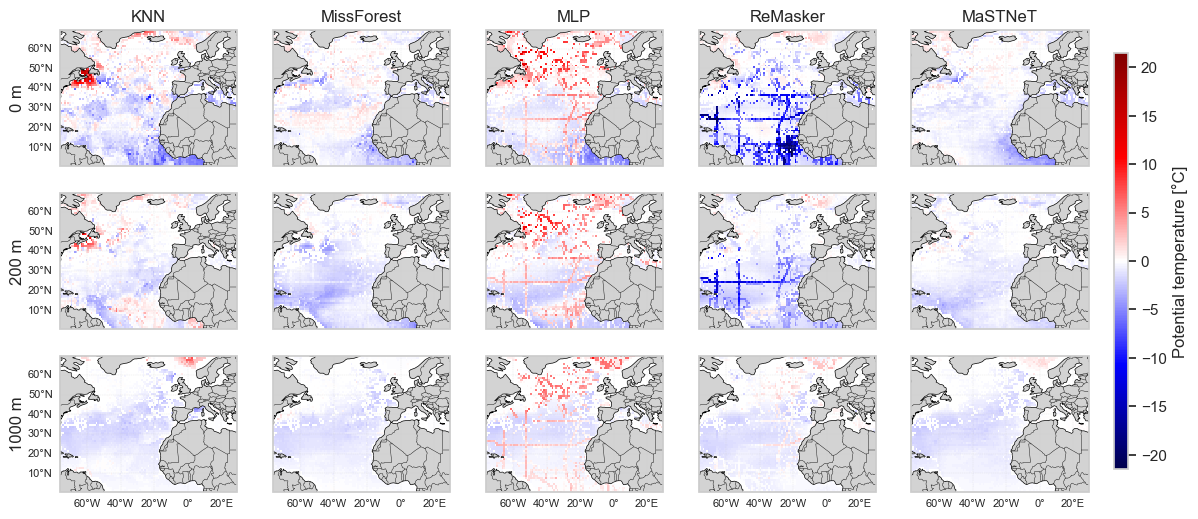

Saved: output/plots/woa_comparison/diff_maps//woa_diff_unscaled_P_SALINITY.png


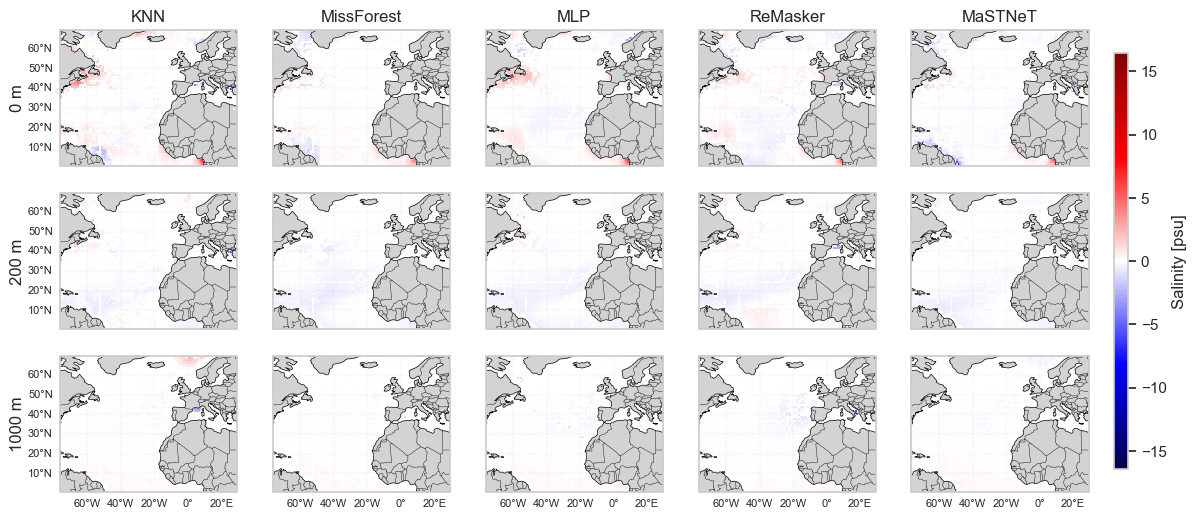

Saved: output/plots/woa_comparison/diff_maps//woa_diff_unscaled_P_OXYGEN.png


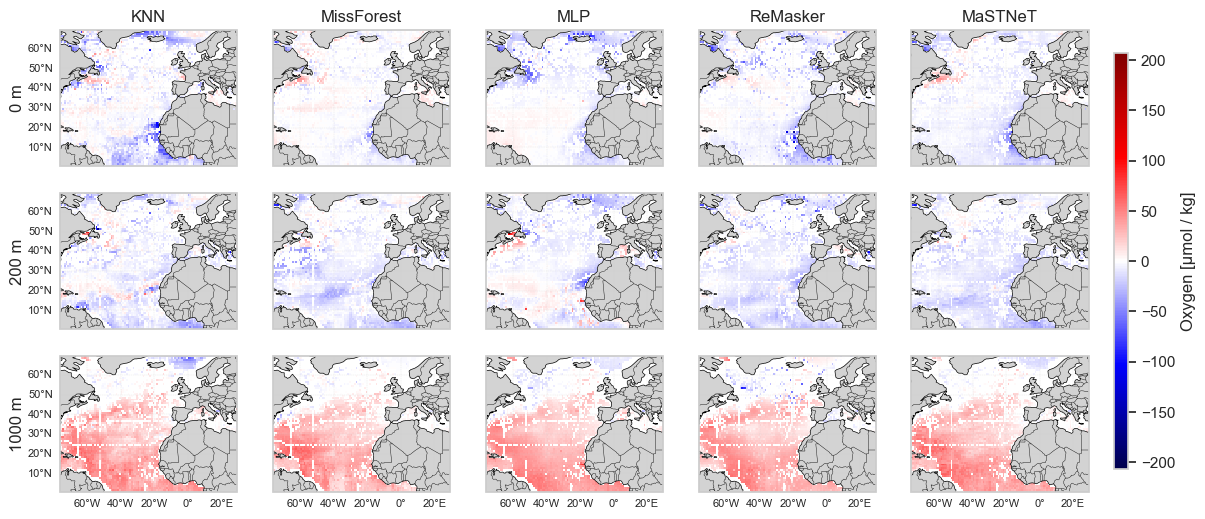

Saved: output/plots/woa_comparison/diff_maps//woa_diff_unscaled_P_NITRATE.png


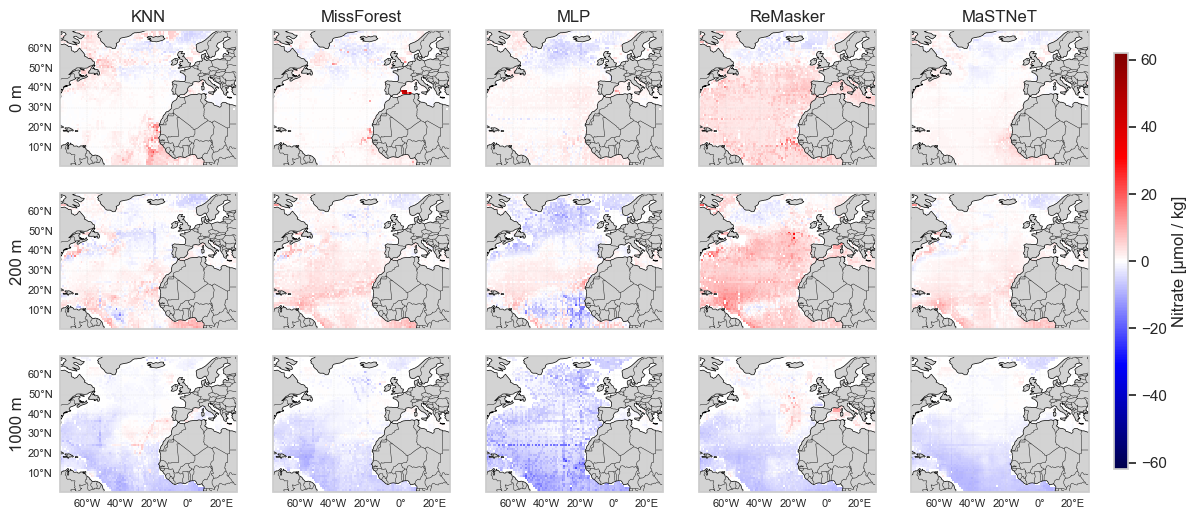

Saved: output/plots/woa_comparison/diff_maps//woa_diff_unscaled_P_SILICATE.png


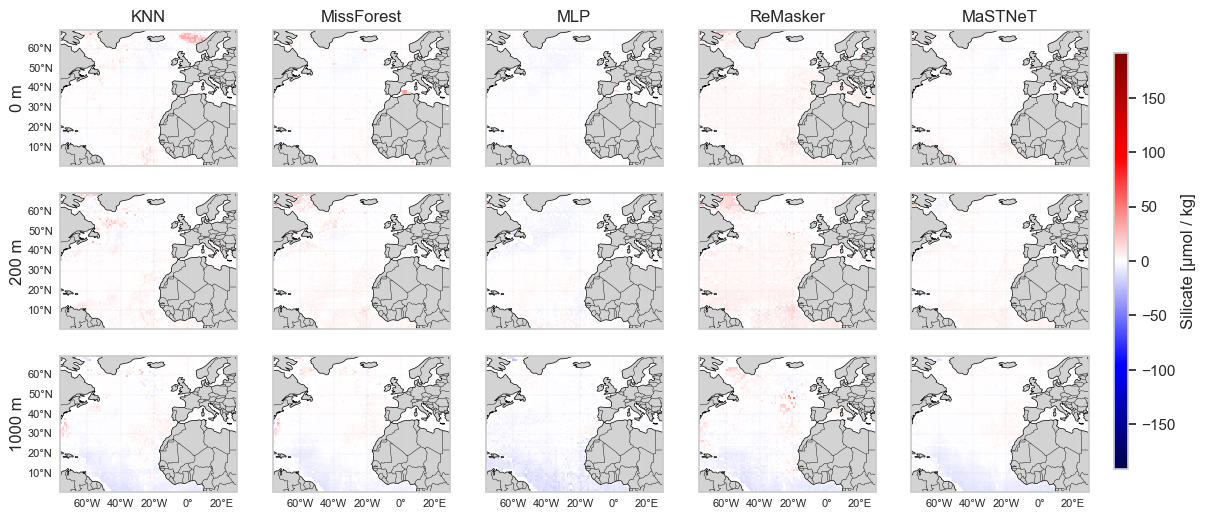

Saved: output/plots/woa_comparison/diff_maps//woa_diff_unscaled_P_PHOSPHATE.png


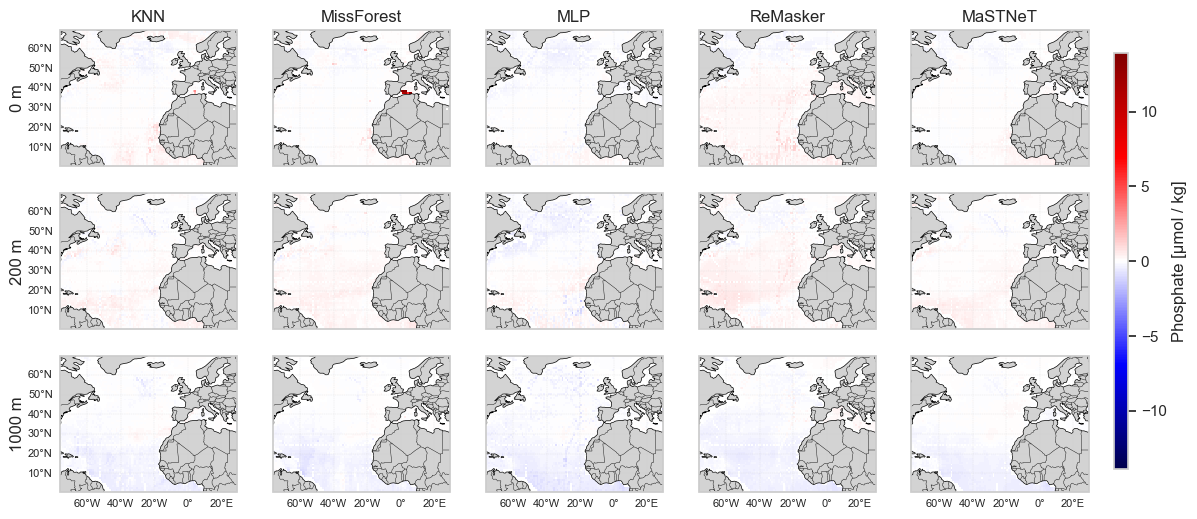

In [8]:
os.makedirs("output/plots/woa_comparison/diff_maps/", exist_ok=True)
sns.set_theme(style="whitegrid")

for parameter in config.parameters:
    # Symmetric colour bounds: same absmax across all models
    absmax = max(
        res_woa[m]["mean"][parameter].abs().max()
        for m in models_to_plot
        if parameter in res_woa[m]["mean"].columns
    )
    norm = mcolors.TwoSlopeNorm(vmin=-absmax, vcenter=0, vmax=absmax)

    # Assemble dict {model_name: mean_diff as xarray}
    gridded = {
        m: df_to_gridded_da(
            res_woa[m]["mean"][res_woa[m]["mean"]["LEV_M"].isin(depths_map)],
            value_col=parameter,
        )
        for m in models_to_plot
    }

    # Plot
    plot_geo_panels(
        get_data=lambda d, m, _g=gridded: _g[m].sel(depth=d),
        row_items=[(d, f"{d} m") for d in depths_map],
        col_items=[(m, config.model_name_map.get(m, m)) for m in models_to_plot],
        plot_config={"cmap": "seismic", "norm": norm},
        colorbar_label=config.parameter_name_unit_map.get(parameter, parameter),
        output_path="output/plots/woa_comparison/diff_maps/",
        filename=f"woa_diff_unscaled_{parameter}.png",
        dpi=300,
    )

# Summary comparison

In [11]:
# Load per-model summary CSVs written by the loop above
summary_rows = []
for model_name in all_model_names:
    csv_path = Path("F:/PhD/phd_repos/time_imputation/output/testing/") / model_name / f"{model_name}_woa_diff_summary_scaled.csv"
    if csv_path.exists():
        df_s = pd.read_csv(csv_path)
        df_s["Model"] = config.model_name_map.get(model_name, model_name)
        summary_rows.append(df_s)
    else:
        print(f"Missing: {csv_path}")

summary = pd.concat(summary_rows, ignore_index=True)
summary["parameter"] = summary["parameter"].map(config.parameter_name_map)

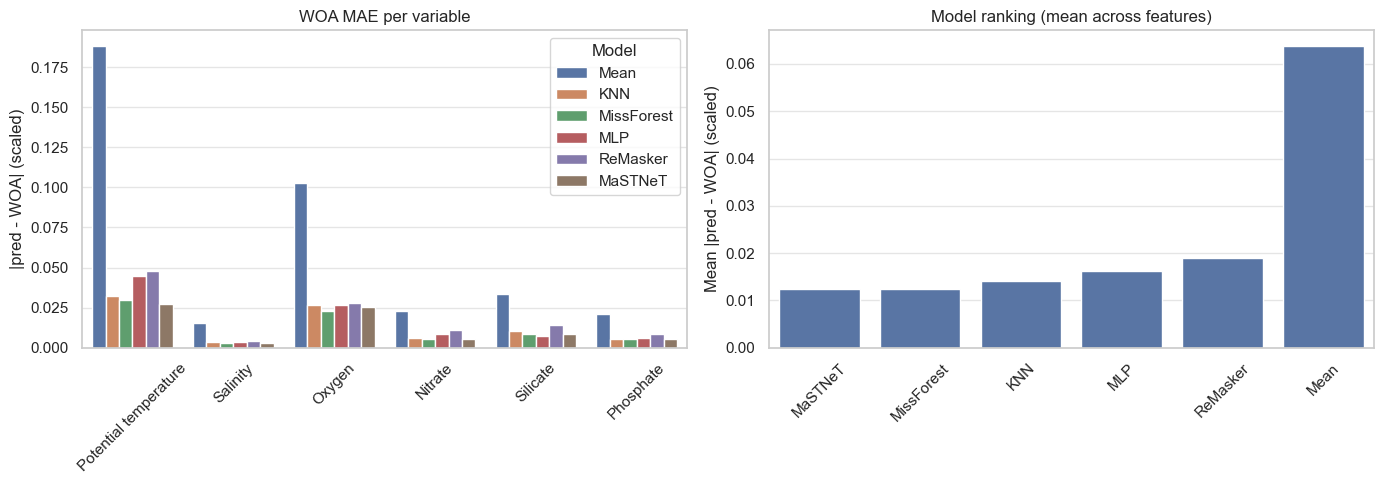

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Per-feature MAE
sns.barplot(data=summary, x="parameter", y="MAE", hue="Model", ax=axes[0])
axes[0].set_xlabel("")
axes[0].set_ylabel("|pred - WOA| (scaled)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("WOA MAE per variable")

# Model ranking (mean across features)
mean_mae = summary.groupby("Model")["MAE"].mean().sort_values().reset_index()
sns.barplot(data=mean_mae, x="Model", y="MAE", ax=axes[1])
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean |pred - WOA| (scaled)")
axes[1].set_title("Model ranking (mean across features)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
os.makedirs("output/plots/woa_comparison/", exist_ok=True)
plt.savefig("output/plots/woa_comparison/woa_mae_summary.png", dpi=300)
plt.show()